<a href="https://colab.research.google.com/github/nivetha486/24ADI204_DSV_Team12/blob/main/DSV_DashBoard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/nivetha486/24ADI204_DSV_Team12/main/WEEK_6/Week6_Feature_Engineered_Dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Original shape: (12500, 79)


,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,...,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies,Gender_Female,Gender_Male,Diagnosis_Encoded
0,1,0.712121,Female,Linear IgA disease,0.218487,0.016667,0.424000,0.596429,0.828276,0.966667,...,0,0,0,0,0,0,0,1,0,65
1,2,0.651515,Male,Dermatomyositis,0.890756,0.612500,0.630667,0.456429,0.661887,0.656667,...,0,0,0,0,1,0,0,0,1,31
2,3,0.363636,Male,Ord's thyroiditis,0.050420,0.170833,0.488000,0.457857,0.441814,0.571667,...,0,0,0,0,0,0,0,0,1,81
3,4,0.409091,Female,Restless legs syndrome,0.092437,0.445833,0.661333,0.292857,0.364788,0.236667,...,0,0,0,0,0,0,0,1,0,93
4,5,0.909091,Female,Autoimmune polyendocrine syndrome type 2 (APS2),0.252101,0.575000,0.161333,0.112857,0.605202,0.645000,...,0,0,0,0,0,0,0,1,0,15


In [4]:
# Remove patient ID and encoded diagnosis
df = df.drop(columns=["Patient_ID", "Diagnosis_Encoded"], errors="ignore")

# Remove redundant gender columns
df = df.drop(columns=["Gender_Female", "Gender_Male"], errors="ignore")

# Identify exact duplicate columns
duplicate_cols = df.columns[df.T.duplicated()].tolist()
print("Duplicate columns:", duplicate_cols)

# Remove exact duplicates
df = df.drop(columns=duplicate_cols)

print("Cleaned shape:", df.shape)
display(df.head())

Duplicate columns: ['Anti_Ro_SSA', 'Anti_BP180', 'Anti_La_SSB', 'Anti_Jo1', 'ANCA', 'Anti_desmoglein_1', 'EMA', 'Anti_TIF1', 'Anti_OmpC', 'anti_Scl_70', 'Anti_Mi2', 'Anti_parietal_cell']
Cleaned shape: (12500, 63)


,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,MCHC,...,IgG_IgE_receptor,Anti_SRP,Anti_desmoglein_3,anti_centromere,Anti_type_VII_collagen,C1_inhibitor,Anti_epidermal_basement_membrane_IgA,pANCA,Anti_tissue_transglutaminase,Progesterone_antibodies
0,0.712121,Female,Linear IgA disease,0.218487,0.016667,0.424000,0.596429,0.828276,0.966667,0.424,...,0,0,0,0,0,0,1,0,0,0
1,0.651515,Male,Dermatomyositis,0.890756,0.612500,0.630667,0.456429,0.661887,0.656667,0.014,...,0,1,0,0,0,0,0,0,0,0
2,0.363636,Male,Ord's thyroiditis,0.050420,0.170833,0.488000,0.457857,0.441814,0.571667,0.922,...,0,0,0,0,0,0,0,0,0,0
3,0.409091,Female,Restless legs syndrome,0.092437,0.445833,0.661333,0.292857,0.364788,0.236667,0.586,...,0,0,0,0,0,0,0,0,0,0
4,0.909091,Female,Autoimmune polyendocrine syndrome type 2 (APS2),0.252101,0.575000,0.161333,0.112857,0.605202,0.645000,0.058,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("Remaining columns:")

for i, col in enumerate(df.columns, 1):
    print(i, col)

Remaining columns:
1 Age
2 Gender
3 Diagnosis
4 Sickness_Duration_Months
5 RBC_Count
6 Hemoglobin
7 Hematocrit
8 MCV
9 MCH
10 MCHC
11 RDW
12 Reticulocyte_Count
13 WBC_Count
14 Neutrophils
15 Lymphocytes
16 Monocytes
17 Eosinophils
18 Basophils
19 PLT_Count
20 MPV
21 ANA
22 Esbach
23 MBL_Level
24 ESR
25 C3
26 C4
27 CRP
28 Anti-dsDNA
29 Anti-Sm
30 Rheumatoid factor
31 ACPA
32 Anti-TPO
33 Anti-Tg
34 Anti-SMA
35 Low-grade fever
36 Fatigue or chronic tiredness
37 Dizziness
38 Weight loss
39 Rashes and skin lesions
40 Stiffness in the joints
41 Brittle hair or hair loss
42 Dry eyes and/or mouth
43 General 'unwell' feeling
44 Joint pain
45 Anti_dsDNA
46 Anti_enterocyte_antibodies
47 anti_LKM1
48 Anti_RNP
49 ASCA
50 Anti_CBir1
51 Anti_BP230
52 DGP
53 Anti_IF
54 IgG_IgE_receptor
55 Anti_SRP
56 Anti_desmoglein_3
57 anti_centromere
58 Anti_type_VII_collagen
59 C1_inhibitor
60 Anti_epidermal_basement_membrane_IgA
61 pANCA
62 Anti_tissue_transglutaminase
63 Progesterone_antibodies


In [6]:
print("Number of diagnosis categories:", df["Diagnosis"].nunique())

print("\nDiagnosis distribution:")

display(
    df["Diagnosis"].value_counts().reset_index()
    )

Number of diagnosis categories: 116

Diagnosis distribution:


,Diagnosis,count
0,Normal,2500
1,Endometriosis,184
2,Dermatomyositis,183
3,Autoimmune oophoritis,170
4,Autoimmune orchitis,162
...,...,...
111,Sydenham's chorea,68
112,Lichen sclerosus,68
113,Rheumatic heart disease,67
114,Polyarteritis nodosa (PAN),63


In [7]:
from google.colab import files

# Save the final cleaned dataset
df.to_csv("Autoimmune_Final_Cleaned_Dataset.csv", index=False)

# Download it to your computer
files.download("Autoimmune_Final_Cleaned_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# Install required libraries
!pip install streamlit plotly scikit-learn -q

# Import libraries
import pandas as pd
import numpy as np
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries installed and imported successfully!")

Libraries installed and imported successfully!


In [9]:
# Import pandas
import pandas as pd

# GitHub dataset URL converted to raw CSV URL
url = "https://raw.githubusercontent.com/nivetha486/24ADI204_DSV_Team12/main/DATASETS/Autoimmune_Final_Cleaned_Dataset.csv"

# Load dataset
df = pd.read_csv(url)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
display(df.head())

Dataset loaded successfully!
Dataset shape: (12500, 63)


,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,MCHC,...,IgG_IgE_receptor,Anti_SRP,Anti_desmoglein_3,anti_centromere,Anti_type_VII_collagen,C1_inhibitor,Anti_epidermal_basement_membrane_IgA,pANCA,Anti_tissue_transglutaminase,Progesterone_antibodies
0,0.712121,Female,Linear IgA disease,0.218487,0.016667,0.424000,0.596429,0.828276,0.966667,0.424,...,0,0,0,0,0,0,1,0,0,0
1,0.651515,Male,Dermatomyositis,0.890756,0.612500,0.630667,0.456429,0.661887,0.656667,0.014,...,0,1,0,0,0,0,0,0,0,0
2,0.363636,Male,Ord's thyroiditis,0.050420,0.170833,0.488000,0.457857,0.441814,0.571667,0.922,...,0,0,0,0,0,0,0,0,0,0
3,0.409091,Female,Restless legs syndrome,0.092437,0.445833,0.661333,0.292857,0.364788,0.236667,0.586,...,0,0,0,0,0,0,0,0,0,0
4,0.909091,Female,Autoimmune polyendocrine syndrome type 2 (APS2),0.252101,0.575000,0.161333,0.112857,0.605202,0.645000,0.058,...,0,0,0,0,0,0,0,0,0,0


In [10]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDiagnosis distribution:")
print(df["Diagnosis"].value_counts())

Column names:
['Age', 'Gender', 'Diagnosis', 'Sickness_Duration_Months', 'RBC_Count', 'Hemoglobin', 'Hematocrit', 'MCV', 'MCH', 'MCHC', 'RDW', 'Reticulocyte_Count', 'WBC_Count', 'Neutrophils', 'Lymphocytes', 'Monocytes', 'Eosinophils', 'Basophils', 'PLT_Count', 'MPV', 'ANA', 'Esbach', 'MBL_Level', 'ESR', 'C3', 'C4', 'CRP', 'Anti-dsDNA', 'Anti-Sm', 'Rheumatoid factor', 'ACPA', 'Anti-TPO', 'Anti-Tg', 'Anti-SMA', 'Low-grade fever', 'Fatigue or chronic tiredness', 'Dizziness', 'Weight loss', 'Rashes and skin lesions', 'Stiffness in the joints', 'Brittle hair or hair loss', 'Dry eyes and/or mouth', "General 'unwell' feeling", 'Joint pain', 'Anti_dsDNA', 'Anti_enterocyte_antibodies', 'anti_LKM1', 'Anti_RNP', 'ASCA', 'Anti_CBir1', 'Anti_BP230', 'DGP', 'Anti_IF', 'IgG_IgE_receptor', 'Anti_SRP', 'Anti_desmoglein_3', 'anti_centromere', 'Anti_type_VII_collagen', 'C1_inhibitor', 'Anti_epidermal_basement_membrane_IgA', 'pANCA', 'Anti_tissue_transglutaminase', 'Progesterone_antibodies']

Dataset inf

In [11]:
# Define target variable
target = "Diagnosis"

# Define symptom columns
symptom_columns = [
    "Low-grade fever",
    "Fatigue or chronic tiredness",
    "Dizziness",
    "Weight loss",
    "Rashes and skin lesions",
    "Stiffness in the joints",
    "Brittle hair or hair loss",
    "Dry eyes and/or mouth",
    "General 'unwell' feeling",
    "Joint pain"
]

# Define blood and clinical measurement columns
blood_columns = [
    "RBC_Count", "Hemoglobin", "Hematocrit",
    "MCV", "MCH", "MCHC", "RDW",
    "Reticulocyte_Count", "WBC_Count",
    "Neutrophils", "Lymphocytes", "Monocytes",
    "Eosinophils", "Basophils", "PLT_Count",
    "MPV", "Esbach", "MBL_Level", "ESR",
    "C3", "C4", "CRP"
]

# Define antibody marker columns
antibody_columns = [
    "ANA", "Anti-dsDNA", "Anti-Sm",
    "Rheumatoid factor", "ACPA", "Anti-TPO",
    "Anti-Tg", "Anti-SMA", "Anti_dsDNA",
    "Anti_enterocyte_antibodies", "anti_LKM1",
    "Anti_RNP", "ASCA", "Anti_CBir1",
    "Anti_BP230", "DGP", "Anti_IF",
    "IgG_IgE_receptor", "Anti_SRP",
    "Anti_desmoglein_3", "anti_centromere",
    "Anti_type_VII_collagen", "C1_inhibitor",
    "Anti_epidermal_basement_membrane_IgA",
    "pANCA", "Anti_tissue_transglutaminase",
    "Progesterone_antibodies"
]

# Define demographic and patient information
patient_columns = [
    "Age",
    "Gender",
    "Sickness_Duration_Months"
]

# Verify columns
for group_name, columns in {
    "Symptoms": symptom_columns,
    "Blood factors": blood_columns,
    "Antibody markers": antibody_columns,
    "Patient information": patient_columns
}.items():
    missing = [col for col in columns if col not in df.columns]
    print(f"\n{group_name}: {len(columns) - len(missing)} columns found")
    if missing:
        print("Columns not found:", missing)

print("\nFeature grouping completed!")


Symptoms: 10 columns found

Blood factors: 22 columns found

Antibody markers: 27 columns found

Patient information: 3 columns found

Feature grouping completed!


In [12]:
import plotly.express as px

# Calculate symptom frequency
symptom_frequency = df[symptom_columns].sum().sort_values(ascending=False).reset_index()
symptom_frequency.columns = ["Symptom", "Patient Count"]

# Convert counts into percentages
symptom_frequency["Percentage"] = (symptom_frequency["Patient Count"] / len(df) * 100)

# Create chart
fig = px.bar(
    symptom_frequency.sort_values("Percentage"),
    x="Percentage",
    y="Symptom",
    orientation="h",
    text="Percentage",
    title="Most Common Symptoms Among Patients",
    color="Percentage",
    color_continuous_scale="Blues"
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    height=550,
    width=950,
    xaxis_title="Patients Reporting Symptom (%)",
    yaxis_title="Symptoms",
    showlegend=False,
    margin=dict(l=180, r=80, t=80, b=60)
)

fig.show()

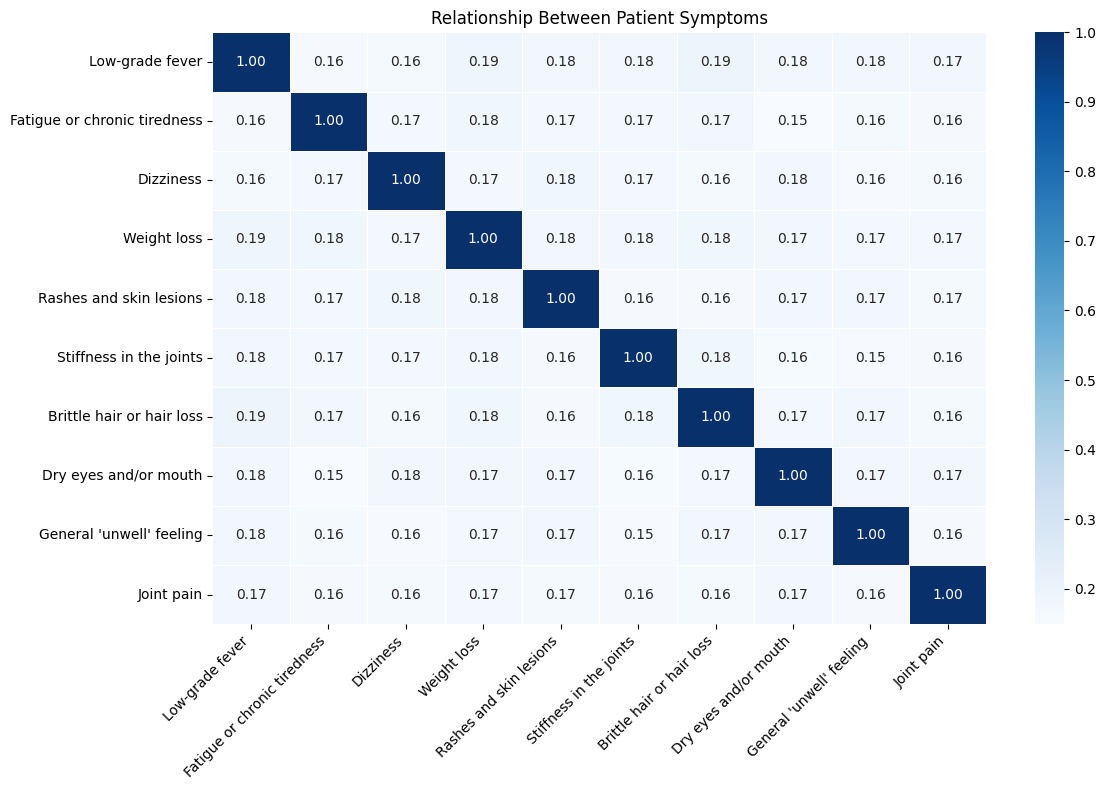

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate symptom correlation
symptom_corr = df[symptom_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    symptom_corr,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Relationship Between Patient Symptoms")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

# Create Streamlit configuration folder
Path(".streamlit").mkdir(exist_ok=True)

# Set a clean light theme
theme_config = """
[theme]
base = "light"
primaryColor = "#3977C3"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#F3F6FA"
textColor = "#263445"
font = "sans serif"
"""

Path(".streamlit/config.toml").write_text(theme_config)

print("Light dashboard theme created successfully!")

Light dashboard theme created successfully!


In [15]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------
st.set_page_config(
    page_title="Autoimmune Disorder Analytics",
    page_icon="🧬",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# STYLE
# --------------------------------------------------
st.markdown("""
<style>
.stApp {
    background-color: #F8FAFC;
    color: #1E293B;
}
[data-testid="stSidebar"] {
    background-color: #EEF3F8;
}
[data-testid="stMetric"] {
    background-color: white;
    border: 1px solid #E2E8F0;
    padding: 15px;
    border-radius: 12px;
}
h1, h2, h3 {
    color: #17365D;
}
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# DATASET URL
# --------------------------------------------------
DATA_URL = (
    "https://raw.githubusercontent.com/nivetha486/"
    "24ADI204_DSV_Team12/main/DATASETS/"
    "Week6_Feature_Engineered_Dataset_Age_Restored.csv"
)

@st.cache_data
def load_data():
    data = pd.read_csv(DATA_URL)
    data.columns = data.columns.str.strip()
    return data

try:
    df = load_data()
except Exception as error:
    st.error("Unable to load the dataset from GitHub.")
    st.code(str(error))
    st.stop()

# --------------------------------------------------
# IDENTIFY IMPORTANT COLUMNS
# --------------------------------------------------
def find_column(name):
    """Find a column without depending on capitalization."""
    for column in df.columns:
        if column.strip().lower() == name.strip().lower():
            return column
    return None

AGE_COL = find_column("Age")
TARGET_COL = find_column("Diagnosis")
GENDER_COL = find_column("Gender")

if AGE_COL is None or TARGET_COL is None:
    st.error(
        "The CSV must contain an Age column and a Diagnosis column. "
        "Please check the column names in your Week 6 dataset."
    )
    st.stop()

# --------------------------------------------------
# SYMPTOM FEATURES
# --------------------------------------------------
SYMPTOM_COLUMNS = [
    "Low-grade fever",
    "Fatigue or chronic tiredness",
    "Dizziness",
    "Weight loss",
    "Rashes and skin lesions",
    "Stiffness in the joints",
    "Brittle hair or hair loss",
    "Dry eyes and/or mouth",
    "General 'unwell' feeling",
    "Joint pain"
]

SYMPTOMS = [
    find_column(column)
    for column in SYMPTOM_COLUMNS
    if find_column(column) is not None
]

# --------------------------------------------------
# TOP 10 SELECTED FEATURES
# --------------------------------------------------
SELECTED_FEATURE_NAMES = [
    "ACPA",
    "CRP",
    "Sickness_Duration_Months",
    "Hemoglobin",
    "RBC_Count",
    "ESR",
    "Hematocrit",
    "MBL_Level",
    "Esbach",
    "ANA"
]

SELECTED_FEATURES = [
    find_column(column)
    for column in SELECTED_FEATURE_NAMES
    if find_column(column) is not None
]

# --------------------------------------------------
# FINAL PREDICTION FEATURE SET
# --------------------------------------------------
PREDICTION_FEATURES = [AGE_COL]
if GENDER_COL is not None:
    PREDICTION_FEATURES.append(GENDER_COL)

PREDICTION_FEATURES += SELECTED_FEATURES
PREDICTION_FEATURES += SYMPTOMS

PREDICTION_FEATURES = list(dict.fromkeys(PREDICTION_FEATURES))
EXCLUDED_COLUMNS = [
    "Patient_ID",
    "Diagnosis_Encoded",
    TARGET_COL
]

MODEL_FEATURES = [
    column for column in PREDICTION_FEATURES
    if column not in EXCLUDED_COLUMNS
]

# --------------------------------------------------
# CLINICAL ANALYSIS GROUPS
# --------------------------------------------------
BLOOD_FEATURES = [
    "CRP",
    "Hemoglobin",
    "RBC_Count",
    "ESR",
    "Hematocrit",
    "Sickness_Duration_Months",
    "MBL_Level",
    "Esbach"
]

ANTIBODY_FEATURES = [
    "ACPA",
    "ANA"
]

BLOOD_FEATURES = [
    find_column(c) for c in BLOOD_FEATURES
    if find_column(c) is not None
]

ANTIBODY_FEATURES = [
    find_column(c) for c in ANTIBODY_FEATURES
    if find_column(c) is not None
]

# --------------------------------------------------
# SIDEBAR NAVIGATION
# --------------------------------------------------
with st.sidebar:
    st.markdown("## 🧬 Autoimmune Analytics")
    st.caption("Patient insights and disease prediction")
    st.divider()
    page = st.selectbox(
        "Navigate to",
        [
            "Overview",
            "Symptom Analysis",
            "Clinical Analysis",
            "Disease Prediction",
            "Model Performance"
        ]
    )
    st.divider()
    st.caption("Dataset: Week 6 Age Restored")
    st.caption(f"Total records: {len(df):,}")
    st.caption(f"Diagnosis categories: {df[TARGET_COL].nunique()}")

# --------------------------------------------------
# HELPER FUNCTIONS
# --------------------------------------------------
def remove_normal(data):
    return data[
        data[TARGET_COL].astype(str).str.strip().str.lower() != "normal"
    ].copy()

def create_metric(label, value):
    st.metric(label, value)

# --------------------------------------------------
# MODEL TRAINING
# --------------------------------------------------
@st.cache_resource
def train_model(data_df):
    X = data_df[MODEL_FEATURES].copy()
    y = data_df[TARGET_COL].astype(str).copy()

    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [col for col in X.columns if col not in numeric_features]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = []
    if numeric_features:
        transformers.append(("numeric", numeric_pipeline, numeric_features))
    if categorical_features:
        transformers.append(("categorical", categorical_pipeline, categorical_features))

    preprocessor = ColumnTransformer(transformers=transformers)
    classifier = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_test, predictions, average="weighted", zero_division=0)
    report = classification_report(y_test, predictions, output_dict=True, zero_division=0)

    feature_names = model.named_steps["preprocessor"].get_feature_names_out()
    importance_values = model.named_steps["classifier"].feature_importances_
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    top_labels = pd.Series(y_test).value_counts().head(12).index.tolist()
    cm = confusion_matrix(y_test, predictions, labels=top_labels)

    return (
        model,
        MODEL_FEATURES,
        accuracy,
        macro_f1,
        weighted_f1,
        report,
        cm,
        importance_df
    )

Overwriting app.py


In [16]:
%%writefile -a app.py

# ==================================================
# 1. OVERVIEW
# ==================================================

if page == "Overview":
    st.title("Autoimmune Disorder Analytics")
    st.write(
        "Explore patient details, diagnosis patterns, symptoms "
        "and selected clinical features."
    )

    col1, col2, col3, col4 = st.columns(4)

    with col1:
        create_metric("Total Records", f"{len(df):,}")

    with col2:
        create_metric("Diagnosis Categories", f"{df[TARGET_COL].nunique()}")

    with col3:
        create_metric(
            "Average Age",
            f"{pd.to_numeric(df[AGE_COL], errors='coerce').mean():.1f} years"
        )

    with col4:
        create_metric("Symptom Features", f"{len(SYMPTOMS)}")

    st.divider()

    left, right = st.columns(2)

    with left:
        st.subheader("Top 10 Diagnosis Categories")
        diagnosis_counts = (
            remove_normal(df)[TARGET_COL]
            .value_counts()
            .head(10)
        )

        fig = px.bar(
            x=diagnosis_counts.values,
            y=diagnosis_counts.index,
            orientation="h",
            labels={
                "x": "Number of Records",
                "y": "Diagnosis"
            },
            color=diagnosis_counts.values,
            color_continuous_scale="Blues"
        )

        fig.update_layout(
            yaxis={"categoryorder": "total ascending"},
            coloraxis_showscale=False,
            height=430
        )

        st.plotly_chart(fig, use_container_width=True)

    with right:
        st.subheader("Age Distribution")
        age_data = pd.to_numeric(
            df[AGE_COL],
            errors="coerce"
        ).dropna()

        fig = px.histogram(
            x=age_data,
            nbins=20,
            labels={
                "x": "Age (years)",
                "y": "Number of Patients"
            },
            color_discrete_sequence=["#3977C3"]
        )

        fig.update_layout(
            height=430,
            xaxis_title="Age (years)",
            yaxis_title="Number of Patients"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.caption(
        f"Age range in the restored dataset: "
        f"{age_data.min():.0f}–{age_data.max():.0f} years."
    )

    st.subheader("Dataset Preview")
    st.dataframe(df.head(10), use_container_width=True)


# ==================================================
# 2. SYMPTOM ANALYSIS
# ==================================================

elif page == "Symptom Analysis":
    st.title("Symptom Analysis")
    st.write(
        "Explore the frequency of symptoms and their patterns "
        "across diagnosis categories."
    )

    if not SYMPTOMS:
        st.warning("The expected symptom columns were not found in the dataset.")
    else:
        symptom_data = df[SYMPTOMS].copy()

        for column in SYMPTOMS:
            symptom_data[column] = pd.to_numeric(
                symptom_data[column],
                errors="coerce"
            )

        symptom_frequency = (symptom_data.mean() * 100).sort_values()

        st.subheader("Symptom Frequency")

        fig = px.bar(
            x=symptom_frequency.values,
            y=symptom_frequency.index,
            orientation="h",
            labels={
                "x": "Patients Reporting Symptom (%)",
                "y": "Symptom"
            },
            color=symptom_frequency.values,
            color_continuous_scale="Blues"
        )

        fig.update_layout(
            yaxis={"categoryorder": "total ascending"},
            coloraxis_showscale=False,
            height=500
        )

        st.plotly_chart(fig, use_container_width=True)

        frequency_table = symptom_frequency.rename("Frequency (%)").reset_index()
        frequency_table.columns = ["Symptom", "Frequency (%)"]

        st.dataframe(
            frequency_table.style.format({"Frequency (%)": "{:.1f}%"}),
            use_container_width=True,
            hide_index=True
        )

        st.divider()
        st.subheader("Symptom Patterns by Diagnosis")

        filtered_data = remove_normal(df)
        top_diagnoses = (
            filtered_data[TARGET_COL]
            .value_counts()
            .head(12)
            .index
        )

        heatmap_data = filtered_data[
            filtered_data[TARGET_COL].isin(top_diagnoses)
        ].copy()

        for column in SYMPTOMS:
            heatmap_data[column] = pd.to_numeric(
                heatmap_data[column],
                errors="coerce"
            )

        heatmap_data = (
            heatmap_data
            .groupby(TARGET_COL)[SYMPTOMS]
            .mean() * 100
        )

        fig = px.imshow(
            heatmap_data,
            aspect="auto",
            color_continuous_scale="Blues",
            labels={
                "x": "Symptoms",
                "y": "Diagnosis",
                "color": "Frequency (%)"
            }
        )

        fig.update_layout(height=550)
        st.plotly_chart(fig, use_container_width=True)


# ==================================================
# 3. CLINICAL ANALYSIS
# ==================================================

elif page == "Clinical Analysis":
    st.title("Clinical Analysis")
    st.write(
        "Explore the ten selected clinical and antibody features "
        "from the feature-selection output."
    )

    blood_tab, antibody_tab = st.tabs([
        "Blood & Clinical Factors",
        "Antibody & Protein Markers"
    ])

    # ----------------------------------------------
    # BLOOD AND CLINICAL FEATURES
    # ----------------------------------------------
    with blood_tab:
        if BLOOD_FEATURES:
            selected_blood = st.selectbox(
                "Select a clinical factor",
                BLOOD_FEATURES
            )

            chart_data = remove_normal(df)
            top_diagnoses = (
                chart_data[TARGET_COL]
                .value_counts()
                .head(10)
                .index
            )

            chart_data = chart_data[
                chart_data[TARGET_COL].isin(top_diagnoses)
            ].copy()

            chart_data[selected_blood] = pd.to_numeric(
                chart_data[selected_blood],
                errors="coerce"
            )

            fig = px.box(
                chart_data,
                x=TARGET_COL,
                y=selected_blood,
                color=TARGET_COL,
                title=f"{selected_blood} by Diagnosis",
                points=False
            )

            fig.update_layout(
                showlegend=False,
                xaxis_tickangle=-35,
                height=500
            )

            st.plotly_chart(fig, use_container_width=True)
        else:
            st.info("No selected blood or clinical features were found.")

    # ----------------------------------------------
    # ANTIBODY AND PROTEIN FEATURES
    # ----------------------------------------------
    with antibody_tab:
        if ANTIBODY_FEATURES:
            selected_marker = st.selectbox(
                "Select an antibody/protein marker",
                ANTIBODY_FEATURES
            )

            marker_data = df[[TARGET_COL, selected_marker]].copy()
            marker_data[selected_marker] = pd.to_numeric(
                marker_data[selected_marker],
                errors="coerce"
            )

            marker_data = (
                marker_data
                .groupby(TARGET_COL)[selected_marker]
                .mean()
                .sort_values(ascending=False)
                .head(15)
                .reset_index()
            )

            fig = px.bar(
                marker_data,
                x=TARGET_COL,
                y=selected_marker,
                color=selected_marker,
                color_continuous_scale="Blues",
                title=f"{selected_marker} by Diagnosis"
            )

            fig.update_layout(
                xaxis_tickangle=-35,
                height=480,
                coloraxis_showscale=False
            )

            st.plotly_chart(fig, use_container_width=True)
        else:
            st.info("No selected antibody/protein markers were found.")

    st.divider()
    st.subheader("Selected Features Used")

    selected_table = pd.DataFrame({
        "Selected Feature": SELECTED_FEATURES
    })

    st.dataframe(
        selected_table,
        use_container_width=True,
        hide_index=True
    )

    st.caption(
        "Only the selected features are included in the clinical "
        "feature analysis and prediction feature set."
    )

Appending to app.py


In [17]:
%%writefile -a app.py

# ==================================================
# 4. DISEASE PREDICTION
# ==================================================
elif page == "Disease Prediction":
    st.title("Disease Prediction")
    st.write(
        "Enter patient information, selected clinical markers "
        "and symptoms to generate a dataset-based prediction."
    )
    st.info(
        "Prediction features: restored Age, Gender (if available), "
        "the 10 selected features and all available symptom fields."
    )

    st.subheader("Patient Information")

    with st.form("disease_prediction_form"):
        input_data = {}

        # ----------------------------------------------
        # PATIENT DETAILS
        # ----------------------------------------------
        patient_columns = st.columns(2)

        with patient_columns[0]:
            age_min = float(pd.to_numeric(df[AGE_COL], errors="coerce").min())
            age_max = float(pd.to_numeric(df[AGE_COL], errors="coerce").max())
            age_default = float(pd.to_numeric(df[AGE_COL], errors="coerce").median())

            input_data[AGE_COL] = st.number_input(
                "Age (years)",
                min_value=age_min,
                max_value=age_max,
                value=age_default,
                step=1.0
            )

        if GENDER_COL is not None:
            with patient_columns[1]:
                gender_options = df[GENDER_COL].dropna().astype(str).unique().tolist()
                input_data[GENDER_COL] = st.selectbox(
                    "Gender",
                    gender_options
                )

        st.divider()

        # ----------------------------------------------
        # SELECTED CLINICAL AND ANTIBODY FEATURES
        # ----------------------------------------------
        st.subheader("Selected Clinical & Antibody Features")
        feature_columns = st.columns(2)

        for index, feature in enumerate(SELECTED_FEATURES):
            series = df[feature].dropna()

            with feature_columns[index % 2]:
                if pd.api.types.is_numeric_dtype(df[feature]):
                    numeric_series = pd.to_numeric(df[feature], errors="coerce").dropna()
                    unique_values = set(numeric_series.unique().tolist())

                    # Binary marker such as 0/1
                    if unique_values.issubset({0, 1}):
                        selected_value = st.selectbox(
                            feature,
                            options=[0, 1],
                            format_func=lambda value: "Positive" if value == 1 else "Negative",
                            key=f"marker_{index}"
                        )
                    else:
                        minimum = float(numeric_series.min())
                        maximum = float(numeric_series.max())
                        default = float(numeric_series.median())

                        selected_value = st.number_input(
                            feature,
                            min_value=minimum,
                            max_value=maximum,
                            value=default,
                            step=0.1,
                            format="%.3f",
                            key=f"marker_{index}"
                        )
                else:
                    options = series.astype(str).unique().tolist()
                    selected_value = st.selectbox(
                        feature,
                        options=options,
                        key=f"marker_{index}"
                    )

                input_data[feature] = selected_value

        st.divider()

        # ----------------------------------------------
        # SYMPTOMS
        # ----------------------------------------------
        st.subheader("Symptoms")
        symptom_columns = st.columns(2)

        for index, symptom in enumerate(SYMPTOMS):
            with symptom_columns[index % 2]:
                if pd.api.types.is_numeric_dtype(df[symptom]):
                    answer = st.selectbox(
                        symptom,
                        options=[0, 1],
                        format_func=lambda value: "Yes" if value == 1 else "No",
                        key=f"symptom_{index}"
                    )
                else:
                    existing_values = df[symptom].dropna().astype(str).unique().tolist()
                    answer = st.selectbox(
                        symptom,
                        options=existing_values,
                        key=f"symptom_{index}"
                    )

                input_data[symptom] = answer

        st.divider()
        submitted = st.form_submit_button(
            "Predict Disease Category",
            use_container_width=True
        )

        # ----------------------------------------------
        # GENERATE PREDICTION
        # ----------------------------------------------
        if submitted:
            try:
                with st.spinner("Generating prediction..."):
                    (
                        model,
                        model_features,
                        accuracy,
                        macro_f1,
                        weighted_f1,
                        report,
                        cm,
                        importance_df
                    ) = train_model(df)

                    model_input = pd.DataFrame(
                        [{feature: input_data[feature] for feature in MODEL_FEATURES}],
                        columns=MODEL_FEATURES
                    )

                    predicted_category = model.predict(model_input)[0]

                    st.success(f"Predicted Dataset Category: {predicted_category}")
                    st.warning(
                        "This prediction is based on patterns in the supplied "
                        "dataset. It is for educational analysis only and is "
                        "not a medical diagnosis or a substitute for professional "
                        "healthcare advice."
                    )
            except Exception as error:
                st.error("Prediction could not be completed.")
                st.code(str(error))


# ==================================================
# 5. MODEL PERFORMANCE
# ==================================================
elif page == "Model Performance":
    st.title("Model Performance")
    st.write(
        "Evaluate the Random Forest model using a stratified "
        "80/20 train-test split."
    )

    try:
        with st.spinner("Training and evaluating the model..."):
            (
                model,
                model_features,
                accuracy,
                macro_f1,
                weighted_f1,
                report,
                cm,
                importance_df
            ) = train_model(df)
    except Exception as error:
        st.error("Model training failed.")
        st.code(str(error))
        st.stop()

    # ----------------------------------------------
    # PERFORMANCE METRICS
    # ----------------------------------------------
    col1, col2, col3 = st.columns(3)

    with col1:
        create_metric("Accuracy", f"{accuracy:.3f}")

    with col2:
        create_metric("Macro F1-score", f"{macro_f1:.3f}")

    with col3:
        create_metric("Weighted F1-score", f"{weighted_f1:.3f}")

    st.caption(
        "Macro F1 gives equal importance to each diagnosis category. "
        "Weighted F1 accounts for the number of records in each category."
    )
    st.divider()

    # ----------------------------------------------
    # FEATURE IMPORTANCE
    # ----------------------------------------------
    st.subheader("Top 15 Feature Importances")
    importance_data = importance_df.head(15).sort_values("Importance", ascending=True)

    fig = px.bar(
        importance_data,
        x="Importance",
        y="Feature",
        orientation="h",
        color="Importance",
        color_continuous_scale="Blues"
    )

    fig.update_layout(
        yaxis={"categoryorder": "total ascending"},
        coloraxis_showscale=False,
        height=550
    )
    st.plotly_chart(fig, use_container_width=True)

    # ----------------------------------------------
    # CLASSIFICATION REPORT
    # ----------------------------------------------
    st.subheader("Classification Report")
    report_df = pd.DataFrame(report).T

    class_report = report_df.drop(
        index=["accuracy", "macro avg", "weighted avg"],
        errors="ignore"
    )
    class_report = class_report.sort_values("support", ascending=False).head(15)

    st.dataframe(
        class_report[["precision", "recall", "f1-score", "support"]].style.format({
            "precision": "{:.3f}",
            "recall": "{:.3f}",
            "f1-score": "{:.3f}",
            "support": "{:.0f}"
        }),
        use_container_width=True
    )

    # ----------------------------------------------
    # CONFUSION MATRIX
    # ----------------------------------------------
    st.subheader("Confusion Matrix — Most Frequent Test Categories")
    top_labels = pd.Series(df[TARGET_COL]).value_counts().head(12).index.tolist()

    fig = px.imshow(
        cm,
        x=top_labels,
        y=top_labels,
        color_continuous_scale="Blues",
        labels={
            "x": "Predicted Diagnosis",
            "y": "Actual Diagnosis",
            "color": "Count"
        },
        aspect="auto"
    )

    fig.update_layout(
        xaxis_tickangle=-45,
        height=650
    )
    st.plotly_chart(fig, use_container_width=True)


# ==================================================
# FOOTER
# ==================================================
st.divider()
st.caption(
    "Autoimmune Disorder Analytics | Educational dataset analysis only. "
    "Predictions are not clinical diagnoses."
)

Appending to app.py


In [24]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [26]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 7s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸

In [ ]:
!lt --port 8501

your url is: https://clever-eggs-follow.loca.lt
